In [1]:
using LinearAlgebra
using SparseArrays
using Plots

In [2]:
function construir_malla(m)
  h = 1.0/(m+1)
  x = collect(1:m) .* h
  y = collect(1:m) .* h
  return x,y,h
end

function construir_laplaciano(m,h)
  e = ones(m)
  A = spdiagm(
    -1 => e[1:m-1],
    0 => -2.0 .* e,
    1 => e[1:m-1]
  )/ h^2
  # AU aplica la diferencia centrada para derivada segunda respecto de x a cada columna de U
  # UA aplica la diferencia centrada para derivada segunda respecto de y a cada fila de U

  I_m = spdiagm(0 => ones(m))

  L = kron(I_m, A) + kron(A, I_m) #operador laplaciano de tamano m^2 * m^2
  # kron(I_m, A)vec(U) calcula la diferencia centrada para derivada segunda respecto de x para cada entrada en U
  # kron(A, I_m)vec(U) calcula la diferencia centrada para derivada segunda respecto de y para cada entrada en U
  # vec(AU)=kron(I_m,A)vec(U)  vec(UA)=kron(A,I_m)vec(U)
  return L
end

construir_laplaciano (generic function with 1 method)

Sea

$$
U=
\begin{pmatrix}
U_{11}&U_{12}&U_{13}\\
U_{21}&U_{22}&U_{23}\\
U_{31}&U_{32}&U_{33}
\end{pmatrix},
$$

donde $U_{ij}$ representa el valor de la solución numérica en el nodo $(x_i,y_j)$.

La matriz de diferencias finitas de segundo orden es

$$
A=\frac{1}{h^2}
\begin{pmatrix}
-2&1&0\\
1&-2&1\\
0&1&-2
\end{pmatrix}.
$$

La matriz identidad de orden 3 es

$$
I_3=
\begin{pmatrix}
1&0&0\\
0&1&0\\
0&0&1
\end{pmatrix}.
$$

$$
I_3\otimes A=
\begin{pmatrix}
A&0&0\\
0&A&0\\
0&0&A
\end{pmatrix}.
$$

$$
\operatorname{vec}(U)=
\begin{pmatrix}
U_{11}\\U_{21}\\U_{31}\\
U_{12}\\U_{22}\\U_{32}\\
U_{13}\\U_{23}\\U_{33}
\end{pmatrix}.
$$

$$
\begin{aligned}
(I_3\otimes A)\operatorname{vec}(U)
&=
\begin{pmatrix}
A&0&0\\
0&A&0\\
0&0&A
\end{pmatrix}
\begin{pmatrix}
U_{11}\\U_{21}\\U_{31}\\
U_{12}\\U_{22}\\U_{32}\\
U_{13}\\U_{23}\\U_{33}
\end{pmatrix}\\[6pt]
&=
\begin{pmatrix}
\dfrac{-2U_{11}+U_{21}}{h^2}\\[4pt]
\dfrac{U_{11}-2U_{21}+U_{31}}{h^2}\\[4pt]
\dfrac{U_{21}-2U_{31}}{h^2}\\[4pt]
\dfrac{-2U_{12}+U_{22}}{h^2}\\[4pt]
\dfrac{U_{12}-2U_{22}+U_{32}}{h^2}\\[4pt]
\dfrac{U_{22}-2U_{32}}{h^2}\\[4pt]
\dfrac{-2U_{13}+U_{23}}{h^2}\\[4pt]
\dfrac{U_{13}-2U_{23}+U_{33}}{h^2}\\[4pt]
\dfrac{U_{23}-2U_{33}}{h^2}
\end{pmatrix}.
\end{aligned}
$$

$$
\begin{aligned}
(A\otimes I_3)\operatorname{vec}(U)
&=
\frac{1}{h^2}
\begin{pmatrix}
-2U_{11}+U_{12}\\
-2U_{21}+U_{22}\\
-2U_{31}+U_{32}\\
U_{11}-2U_{12}+U_{13}\\
U_{21}-2U_{22}+U_{23}\\
U_{31}-2U_{32}+U_{33}\\
U_{12}-2U_{13}\\
U_{22}-2U_{23}\\
U_{32}-2U_{33}
\end{pmatrix}.
\end{aligned}
$$


$$
L\operatorname{vec}(U)
=
\operatorname{vec}
\left(
\begin{pmatrix}
\delta_x^2U_{11}&\delta_x^2U_{12}&\delta_x^2U_{13}\\
\delta_x^2U_{21}&\delta_x^2U_{22}&\delta_x^2U_{23}\\
\delta_x^2U_{31}&\delta_x^2U_{32}&\delta_x^2U_{33}
\end{pmatrix}
+
\begin{pmatrix}
\delta_y^2U_{11}&\delta_y^2U_{12}&\delta_y^2U_{13}\\
\delta_y^2U_{21}&\delta_y^2U_{22}&\delta_y^2U_{23}\\
\delta_y^2U_{31}&\delta_y^2U_{32}&\delta_y^2U_{33}
\end{pmatrix}
\right).
$$

In [3]:
g(x,y) = (x-x^2) * (y-y^2)
f(x,y,t) = 0


f (generic function with 1 method)

## Método explícito

Partimos de la ecuación del calor:

$$
u_t=a\Delta u+f.
$$

Aproximamos la derivada temporal mediante una diferencia
hacia adelante y el Laplaciano mediante diferencias centrales:

$$
\frac{U_{ij}^{n+1}-U_{ij}^{n}}{\Delta t}
=
a\left(\delta_x^2 U_{ij}^{n}
+\delta_y^2 U_{ij}^{n}\right)
+f(x_i,y_j,t_n).
$$

Despejando $U_{ij}^{n+1}$, obtenemos el esquema explícito:

$$
\boxed{
U_{ij}^{n+1}
=
U_{ij}^{n}
+a\Delta t\left(
\delta_x^2 U_{ij}^{n}
+\delta_y^2 U_{ij}^{n}
\right)
+\Delta t\,f(x_i,y_j,t_n)
}
$$

donde

$$
\delta_x^2 U_{ij}^{n}
=
\frac{U_{i+1,j}^{n}-2U_{ij}^{n}+U_{i-1,j}^{n}}{h_x^2},
$$

$$
\delta_y^2 U_{ij}^{n}
=
\frac{U_{i,j+1}^{n}-2U_{ij}^{n}+U_{i,j-1}^{n}}{h_y^2}.
$$

Definimos el vector de incógnitas en el instante $t_n$:

$$
U^n=\operatorname{vec}(U^n_{ij})
\in\mathbb{R}^{(I-1)(J-1)}.
$$

Sea $L_h$ la matriz del Laplaciano discreto, que aproxima
el operador $\Delta u=u_{xx}+u_{yy}$, y sea $F^n$ el vector
de valores de la fuente en el instante $t_n$.

El esquema explícito es

$$
\boxed{
\frac{U^{n+1}-U^n}{\Delta t}
=aL_hU^n+F^n
}
$$

Despejando $U^{n+1}$, obtenemos

$$
\boxed{
U^{n+1}
=(I+a\Delta t L_h)U^n+\Delta t F^n.
}
$$

In [4]:
function inicializar(m,g)
  x,y,h = construir_malla(m)
  U = [g(x[i],y[i]) for i in 1:m, j in 1:m] #valores de g en los puntos interiores
  return x,y,h,U
end

function resolver_explicito(m,dt,T,a,g,f)
  x,y,h,U = inicializar(m,g)
  N = ceil(Int,T/dt) #cantidad de pasos en tiempo
  dt_real = T/N
  L = construir_laplaciano(m,h)

  historia = zeros(m,m,N+1)
  #genera N+1 matrices de ceros de tamaño m para guardar el dato inicial y las aproximaciones en cada paso
  historia[:,:,1] = U

  for n in 1:N
    t = (n-1) * dt_real
    F = [f(x[i],y[i],t) for i in 1:m, j in 1:m] #valores del termino fuente en puntos interiores
    u = vec(U)  #vec convierte a una matriz en un vector por orden de columnas
    Fv = vec(F)

    u_nuevo = u + dt_real * (a*(L*u) + Fv) #el esquema explicito
    U = reshape(u_nuevo,m,m) #convertir el vector en una matriz
    historia[:,:,n+1] = U
  end

  return x,y,dt_real,historia

end



resolver_explicito (generic function with 1 method)

## Método de Crank–Nicolson

Aproximamos la derivada temporal mediante una diferencia
hacia adelante y el término espacial mediante el promedio
entre los instantes $t_n$ y $t_{n+1}$:

$$
\frac{U_{ij}^{n+1}-U_{ij}^{n}}{\Delta t}
=
\frac{a}{2}
\left[
\delta_x^2 U_{ij}^{n+1}
+\delta_y^2 U_{ij}^{n+1}
+\delta_x^2 U_{ij}^{n}
+\delta_y^2 U_{ij}^{n}
\right]
+\frac12\left(f_{ij}^{n+1}+f_{ij}^{n}\right).
$$

Despejando los términos correspondientes al instante
$t_{n+1}$, obtenemos el esquema de Crank–Nicolson:

$$
\boxed{
\begin{aligned}
U_{ij}^{n+1}
&-\frac{a\Delta t}{2}
\left(\delta_x^2 U_{ij}^{n+1}
+\delta_y^2 U_{ij}^{n+1}\right)\\
&=
U_{ij}^{n}
+\frac{a\Delta t}{2}
\left(\delta_x^2 U_{ij}^{n}
+\delta_y^2 U_{ij}^{n}\right)\\
&\quad+\frac{\Delta t}{2}
\left(f_{ij}^{n+1}+f_{ij}^{n}\right).
\end{aligned}
}
$$

donde

$$
f_{ij}^{n}=f(x_i,y_j,t_n),
\qquad
f_{ij}^{n+1}=f(x_i,y_j,t_{n+1}).
$$

En forma matricial

$$
\frac{U^{n+1}-U^n}{\Delta t}
=
\frac{a}{2}L_h(U^{n+1}+U^n)
+\frac12(F^{n+1}+F^n).
$$

Reordenando los términos, resulta

$$
\boxed{
\left(I-\frac{a\Delta t}{2}L_h\right)U^{n+1}
=
\left(I+\frac{a\Delta t}{2}L_h\right)U^n
+\frac{\Delta t}{2}(F^{n+1}+F^n).
}
$$

Definimos las matrices

$$
A=I-\frac{a\Delta t}{2}L_h,
\qquad
B=I+\frac{a\Delta t}{2}L_h.
$$

Así, en cada paso temporal debemos resolver el sistema lineal

$$
\boxed{
AU^{n+1}
=
BU^n+\frac{\Delta t}{2}(F^{n+1}+F^n).
}
$$

In [5]:
function resolver_cn(m,dt,T,a,g,f)
  x,y,h,U = inicializar(m,g)
  N = ceil(Int,T/dt)
  dt_real = T/N
  L = construir_laplaciano(m,h)
  nvar = m^2
  Id = spdiagm(0 => ones(nvar))

  A = Id - (a * dt_real/2) * L
  B = Id + (a * dt_real/2) * L

  historia = zeros(m,m,N+1)
  historia[:,:,1] = U

  for n in 1:N
    t_n = (n-1) * dt_real
    t_np1 = n * dt_real
    F_n = [f(x[i],y[i],t_n) for i in 1:m, j in 1:m]
    F_np1 = [f(x[i],y[i],t_np1) for i in 1:m, j in 1:m]
    u = vec(U)

    derecha = B * u + (dt_real/2) * (vec(F_n) + vec(F_np1))
    u_nuevo = A\derecha #resolviendo U en tiempo n+1
    U = reshape(u_nuevo,m,m)
    historia[:,:,n+1] = U
  end

  return x,y,dt_real,historia
end




resolver_cn (generic function with 1 method)

In [6]:
m = 20
a = 1.0
T = 0.1
dt = 0.0004

x_exp, y_exp, dt_exp, hist_exp =
    resolver_explicito(m, dt, T, a, g, f)

x_cn, y_cn, dt_cn, hist_cn =
    resolver_cn(m, dt, T, a, g, f)

println("Paso temporal explícito: ", dt_exp)
println("Paso temporal C-N: ", dt_cn)
println("Dimensiones de la historia: ", size(hist_exp))


Paso temporal explícito: 0.0004
Paso temporal C-N: 0.0004
Dimensiones de la historia: (20, 20, 251)


In [8]:
function graficar_evolucion(x, y, dt, historia, titulo)
    N = size(historia, 3) - 1
    m = length(x)

    indices = [1, div(N, 2) + 1, N + 1]

    zmax = maximum(historia)
    zmin = min(0.0, minimum(historia))

    p = plot(
        layout = (1, 3),
        size = (1000, 400),
        plot_title = titulo
    )

    for k in 1:3
        idx = indices[k]
        U = historia[:, :, idx]

        # Líneas en la dirección x
        for j in 1:m
            plot!(
                p[k],
                x, fill(y[j], m), U[:, j],
                color = :black,
                linewidth = 0.7,
                label = false
            )
        end

        # Líneas en la dirección y
        for i in 1:m
            plot!(
                p[k],
                fill(x[i], m), y, U[i, :],
                color = :black,
                linewidth = 0.7,
                label = false
            )
        end

        plot!(
            p[k],
            title = "t = $(round((idx - 1) * dt, digits=4))",
            xlabel = "x",
            ylabel = "y",
            zlabel = "u(x,y,t)",
            zlims = (zmin, zmax),
            camera = (45, 30),
            legend = false
        )
    end

    return p
end



graficar_evolucion (generic function with 1 method)

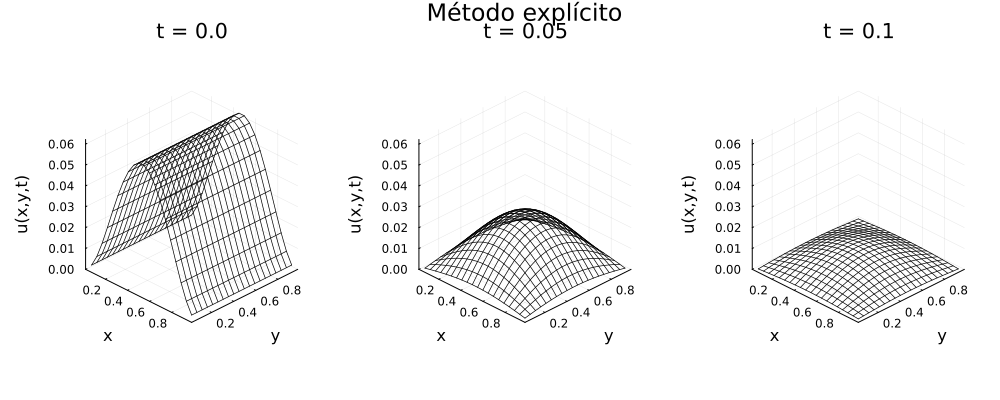

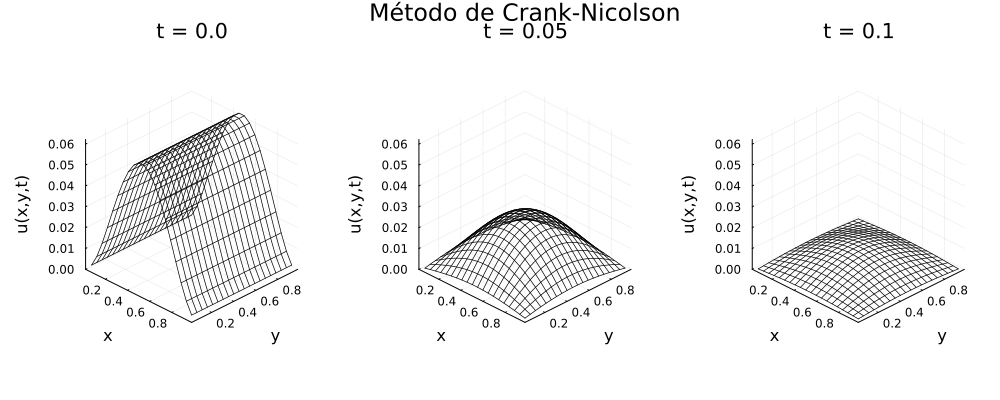

In [12]:
display(graficar_evolucion(
    x_exp, y_exp, dt_exp, hist_exp,
    "Método explícito"
))

display(graficar_evolucion(
    x_cn,
    y_cn,
    dt_cn,
    hist_cn,
    "Método de Crank-Nicolson"
))

Ejercicio 2

In [15]:
h=1/21
dt_limite = h^2 / (4 * a)

println("Límite teórico: ", dt_limite)

dts = [0.0002, 0.0004, 0.00055, 0.0008, 0.001, 0.005]

m = 20
T = 0.1
a = 1.0

println("Metodo explicito")
println("------------------------------------------------")

for dt in dts
    x, y, dt_real, historia =
        resolver_explicito(m, dt, T, a, g, f)

    max_final = maximum(abs.(historia[:, :, end])) #modulo de la solucion numerica en el tiempo final
    max_global = maximum(abs.(historia))

    println("dt = ", dt_real,
            " | max_final = ", max_final,
            " | max_global = ", max_global)
end

Límite teórico: 0.0005668934240362811
Metodo explicito
------------------------------------------------
dt = 0.0002 | max_final = 0.00977431501825127 | max_global = 0.06221687465613608
dt = 0.0004 | max_final = 0.009736206836910514 | max_global = 0.06221687465613608
dt = 0.0005494505494505495 | max_final = 0.009707693340770148 | max_global = 0.06221687465613608
dt = 0.0008 | max_final = 1.132730762939564e24 | max_global = 1.132730762939564e24
dt = 0.001 | max_final = 1.9328123337629886e32 | max_global = 1.9328123337629886e32
dt = 0.005 | max_final = 1.7411401000791268e18 | max_global = 1.7411401000791268e18


In [16]:
println("Metodo Crank-Nicolson")
println("------------------------------------------------")

for dt in dts
    x, y, dt_real, historia =
        resolver_cn(m, dt, T, a, g, f)

    max_final = maximum(abs.(historia[:, :, end]))
    max_global = maximum(abs.(historia))

    println("dt = ", dt_real,
            " | max_final = ", max_final,
            " | max_global = ", max_global)
end


Metodo Crank-Nicolson
------------------------------------------------
dt = 0.0002 | max_final = 0.009812341490700486 | max_global = 0.06221687465613608
dt = 0.0004 | max_final = 0.009812267121120431 | max_global = 0.06221687465613608
dt = 0.0005494505494505495 | max_final = 0.009812179180504884 | max_global = 0.06221687465613608
dt = 0.0008 | max_final = 0.00981196963408695 | max_global = 0.06221687465613608
dt = 0.001 | max_final = 0.009811746509662411 | max_global = 0.06221687465613608
dt = 0.005 | max_final = 0.00979685401537514 | max_global = 0.06221687465613608



## Conclusiones sobre la estabilidad

Para el método explícito, la condición teórica de estabilidad es

$$
a\Delta t\left(\frac{1}{h_x^2}
+\frac{1}{h_y^2}\right)\leq\frac12.
$$

En el caso $h_x=h_y=h$, esta condición se reduce a

$$
\Delta t\leq\frac{h^2}{4a}.
$$

Los experimentos permiten comparar un paso temporal que
satisface esta condición con otro que la viola.

Para el método de Crank-Nicolson, el análisis de Fourier
muestra que el factor de amplificación satisface

$$
|G_{\mathrm{CN}}|\leq1
$$

para cualquier $\Delta t>0$. Por lo tanto, el método es
incondicionalmente estable para la ecuación lineal del calor.




In [53]:
resolver_explicito(m, dt, T, a, g, f)
resolver_cn(m, dt, T, a, g, f)

println("Método explícito:")
@time resolver_explicito(m, dt, T, a, g, f)

println("\nMétodo de Crank-Nicolson:")
@time resolver_cn(m, dt, T, a, g, f)


Método explícito:
  0.001667 seconds (6.62 k allocations: 5.598 MiB)

Método de Crank-Nicolson:
  0.075090 seconds (22.51 k allocations: 67.949 MiB, 9.64% gc time)


([0.047619047619047616, 0.09523809523809523, 0.14285714285714285, 0.19047619047619047, 0.23809523809523808, 0.2857142857142857, 0.3333333333333333, 0.38095238095238093, 0.42857142857142855, 0.47619047619047616, 0.5238095238095237, 0.5714285714285714, 0.6190476190476191, 0.6666666666666666, 0.7142857142857142, 0.7619047619047619, 0.8095238095238095, 0.8571428571428571, 0.9047619047619047, 0.9523809523809523], [0.047619047619047616, 0.09523809523809523, 0.14285714285714285, 0.19047619047619047, 0.23809523809523808, 0.2857142857142857, 0.3333333333333333, 0.38095238095238093, 0.42857142857142855, 0.47619047619047616, 0.5238095238095237, 0.5714285714285714, 0.6190476190476191, 0.6666666666666666, 0.7142857142857142, 0.7619047619047619, 0.8095238095238095, 0.8571428571428571, 0.9047619047619047, 0.9523809523809523], 0.0004, [0.002056756186979705 0.002056756186979705 … 0.002056756186979705 0.002056756186979705; 0.0074248898349967354 0.0074248898349967354 … 0.0074248898349967354 0.00742488983

En este experimento, el método de Crank-Nicolson tardó
aproximadamente $35.5$ veces más que el método explícito.

La diferencia se debe principalmente a que el método
explícito calcula directamente el siguiente paso temporal,
mientras que Crank-Nicolson requiere resolver un sistema
lineal en cada paso.